# Vogelgeluiden herkennen — eerste basismodel

Dit notebook traint een **eenvoudig convolutioneel neuraal netwerk (CNN)** op de
vijf vogelsoorten in `vogel_dataset_v1`. Elke opname heeft één hoofdlabel.
De invoer bestaat uit de al gemaakte log-Mel-spectrogrammen; de uitvoer is één vogelsoort.

De opbouw volgt het bloemenvoorbeeld: gegevens bekijken → verdelen → model bouwen →
trainen → resultaten beoordelen. Bij bloemen worden ook objecten gelokaliseerd.
Hier classificeren we een compleet geluidsfragment, dus gebruiken we geen
bounding boxes, objectdetector of mAP.

**Aansluiting op je onderzoek.** Dit is de baseline uit het *PvA Master piece AI
vogelherkenning* (hoofdstukken 2 en 3) en het *Theoretisch kader Master piece AI
vogelherkenning* (hoofdstukken 3, 4, 7 en 8): een klein CNN, vanaf nul getraind,
CrossEntropyLoss en evaluatie met accuracy, precision, recall, F1 en een confusion matrix.
Augmentatie, transfer learning en experimenten met achtergrondgeluid zijn vervolgstappen.

**Gebruik:** open dit notebook in deze projectmap, selecteer de Python-kernel
`fontys-ml` en kies **Restart Kernel and Run All Cells**. Elke codestap heeft
hieronder een eigen Nederlandse uitleg. De opgeslagen uitvoer laat een werkelijk
uitgevoerde eerste run zien; opnieuw uitvoeren berekent alle resultaten opnieuw.

De bestaande CSV, audio en spectrogrammen worden alleen gelezen. Resultaten komen
in `resultaten/vogelgeluiden_baseline_v1`; opnieuw uitvoeren vervangt daar de uitvoerbestanden.

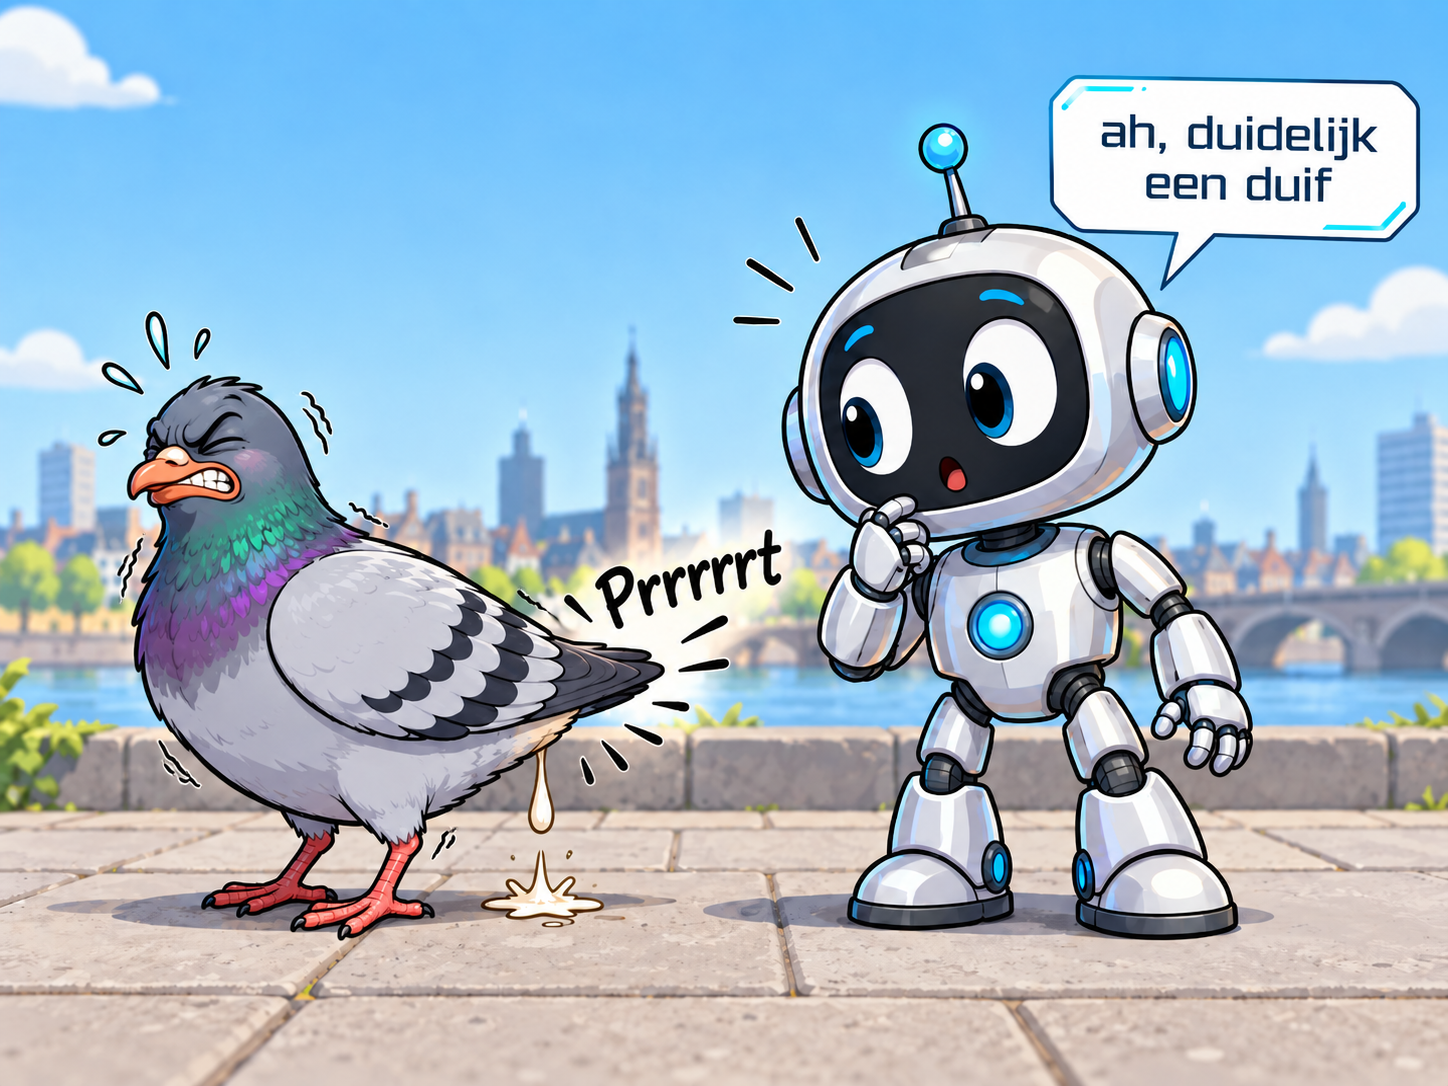

*Afbeelding van R. Bouland: robot herkent poep-geluidje van duif*

## 1. Bibliotheken en instellingen

We gebruiken NumPy en pandas om gegevens te lezen, PyTorch voor het CNN,
scikit-learn voor de verdeling en scores, en Matplotlib voor grafieken.
`SEED = 42` legt de willekeurige keuzes vast. Dit maakt herhalen in dezelfde
omgeving beter reproduceerbaar; andere hardware of pakketversies kunnen verschillen geven.

We trainen vooraf afgesproken **30 epochs** (30 rondes door de trainingsset),
met batches van 16 en een learning rate van 0,001. Deze eerste versie bevat geen
zoektocht naar optimale instellingen. Een beschikbare NVIDIA-GPU wordt automatisch
gebruikt; op de CPU werkt dit kleine model ook. De uitvoer vermeldt het gebruikte apparaat.

Ontbreken pakketten in een nieuwe omgeving, installeer dan eenmalig
`python -m pip install -r requirements-notebook.txt` in je gekozen Python-omgeving
en herstart de kernel. In je bestaande `fontys-ml`-omgeving zijn de benodigde pakketten aanwezig.

In [1]:
import copy
import hashlib
import json
import platform
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import Audio, Markdown, display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
EPOCHS = 30
BATCH_SIZE = 16
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_num_threads(min(4, torch.get_num_threads()))
apparaat = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

versies = {
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'torch': torch.__version__,
    'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__,
}
print('Apparaat:', apparaat)
print('Pakketversies:', versies)

Apparaat: cpu
Pakketversies: {'python': '3.12.3', 'numpy': '2.5.2', 'pandas': '3.0.5', 'torch': '2.14.0+cu130', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1'}


## 2. De dataset en labels lezen

We zoeken de projectmap vanaf de huidige werkmap en lezen `dataset_v1.csv`.
De paden in de CSV zijn relatief aan de projectmap. We houden de bestaande
`label_id`-waarden aan: 0 = merel, 1 = roodborst, 2 = koolmees,
3 = vink en 4 = huismus.

De controles stoppen het notebook met een duidelijke melding als de verwachte
125 opnamen, vijf soorten, unieke Xeno-canto-ID's of labelkoppelingen ontbreken.
De tabel laat ook zien dat elke soort 25 voorbeelden heeft.

In [2]:
projectmap = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'vogel_dataset_v1' / 'dataset_v1.csv').is_file()),
    None,
)
if projectmap is None:
    raise FileNotFoundError('Open het notebook vanuit de projectmap met vogel_dataset_v1.')

csv_pad = projectmap / 'vogel_dataset_v1' / 'dataset_v1.csv'
resultaatmap = projectmap / 'resultaten' / 'vogelgeluiden_baseline_v1'
df = pd.read_csv(csv_pad).sort_values(['label_id', 'xc_id']).reset_index(drop=True)

vereiste_kolommen = {'xc_id', 'label_id', 'klasse', 'bestandspad', 'spec_pad'}
if not vereiste_kolommen.issubset(df.columns):
    raise ValueError(f'Ontbrekende kolommen: {vereiste_kolommen - set(df.columns)}')
if len(df) != 125 or df['xc_id'].nunique() != 125:
    raise ValueError('Voor deze baseline verwachten we 125 rijen met unieke xc_id-waarden.')

soortnamen = ['Merel', 'Roodborst', 'Koolmees', 'Vink', 'Huismus']
wetenschappelijke_namen = [
    'Turdus merula', 'Erithacus rubecula', 'Parus major',
    'Fringilla coelebs', 'Passer domesticus',
]
verwachte_labels = dict(enumerate(wetenschappelijke_namen))
werkelijke_labels = df[['label_id', 'klasse']].drop_duplicates()
if (len(werkelijke_labels) != 5
        or dict(werkelijke_labels.itertuples(index=False, name=None)) != verwachte_labels):
    raise ValueError('De label-ID’s en soortnamen passen niet bij deze vijf soorten.')
if not df.groupby('label_id').size().eq(25).all():
    raise ValueError('Deze baseline verwacht 25 opnamen per soort.')

df['vogelsoort'] = df['label_id'].map(dict(enumerate(soortnamen)))
print('Projectmap:', projectmap)
print(f'Totaal: {len(df)} opnamen en {len(soortnamen)} soorten.')
display(df.groupby(['label_id', 'vogelsoort', 'klasse']).size().rename('aantal').to_frame())

Projectmap: /home/rudy/NextcloudFontys/Master Docent ICT/Semester 3/Masterpiece/dutch-bird-sounds
Totaal: 125 opnamen en 5 soorten.


,,,aantal
label_id,vogelsoort,klasse,
0,Merel,Turdus merula,25
1,Roodborst,Erithacus rubecula,25
2,Koolmees,Parus major,25
3,Vink,Fringilla coelebs,25
4,Huismus,Passer domesticus,25


## 3. Spectrogrammen controleren en inladen

`download.py` heeft per opname een mono-fragment van vier seconden op 22.050 Hz
gemaakt. `convert.py` heeft die omgezet naar log-Mel-spectrogrammen: 128 Mel-banden
bij 173 tijdstappen, per fragment genormaliseerd naar waarden tussen 0 en 1.
We gebruiken deze `.npy`-bestanden rechtstreeks; opnieuw converteren is niet nodig.

Een `.npy` bevat getallen, geen gewone kleurenafbeelding. We controleren de vorm,
eindige waarden en het bereik. Ook berekenen we een hash: een vingerafdruk van de
inhoud waarmee exact gelijke spectrogrammen worden herkend.

**Aangetroffen datakwestie:** XC1167062 en XC1167063 (koolmees) bevatten exact
dezelfde audio en hetzelfde spectrogram. Daarom zijn er 125 bestanden, maar
124 unieke spectrogrammen. Beide blijven in de dataset en worden straks bij elkaar
gehouden. Dat voorkomt overlap tussen sets; de dubbele opname telt binnen haar
eigen set nog wel twee keer mee. De tabel hieronder controleert dit opnieuw.

In [3]:
spectrogrammen = []
hashes = []
for rij in df.itertuples(index=False):
    pad = projectmap / rij.spec_pad
    if not pad.is_file():
        raise FileNotFoundError(f'Spectrogram ontbreekt: {pad}')
    spec = np.load(pad, allow_pickle=False)
    if (spec.shape != (128, 173) or not np.isfinite(spec).all()
            or spec.min() < -1e-6 or spec.max() > 1 + 1e-6):
        raise ValueError(f'Onverwachte vorm of waarden in {pad}')
    spec = spec.astype(np.float32)
    spectrogrammen.append(spec)
    hashes.append(hashlib.sha256(spec.tobytes()).hexdigest())

X = np.stack(spectrogrammen)
y = df['label_id'].to_numpy(dtype=np.int64, copy=True)
df['spec_hash'] = hashes
if df.groupby('spec_hash')['label_id'].nunique().gt(1).any():
    raise ValueError('Een identiek spectrogram heeft verschillende labels. Controleer de dataset.')

print('Vorm van X:', X.shape, '= (opnamen, Mel-banden, tijdstappen)')
print(f'Bereik: {X.min():.3f} tot {X.max():.3f}')
print(f'Unieke spectrogrammen: {df.spec_hash.nunique()} van {len(df)}')
display(df.loc[df.spec_hash.duplicated(keep=False),
               ['xc_id', 'vogelsoort', 'spec_pad']])

Vorm van X: (125, 128, 173) = (opnamen, Mel-banden, tijdstappen)
Bereik: 0.000 tot 1.000
Unieke spectrogrammen: 124 van 125


,xc_id,vogelsoort,spec_pad
58,1167062,Koolmees,vogel_dataset_v1/spectrograms_npy/Parus_major/...
59,1167063,Koolmees,vogel_dataset_v1/spectrograms_npy/Parus_major/...


## 4. De vogelsoorten en hun spectrogrammen bekijken

In de **bovenste rij** zie je de vijf vogelsoorten: merel, roodborst, koolmees,
vink en huismus. De illustraties hebben allemaal hetzelfde formaat van
400 × 340 pixels; hun oorspronkelijke verhoudingen zijn behouden met witte
ruimte eromheen. Zo kun je zien hoe de soorten eruitzien. Deze afbeeldingen
dienen alleen ter illustratie: het model leert uitsluitend van de spectrogrammen.

In de **onderste rij** staat per soort één bestaand spectrogram. Horizontaal
staat de tijd; verticaal het nummer van de Mel-band. De Mel-schaal is niet
lineair in Hertz, dus we benoemen deze as als Mel-banden. Geel staat voor
relatief veel energie, donkerpaars voor relatief weinig energie binnen dit fragment.

Kleuren zijn alleen voor onze weergave: het model krijgt de oorspronkelijke
getallen tussen 0 en 1. Door de normalisatie per fragment kun je de absolute
geluidssterkte van verschillende opnamen hier niet vergelijken.

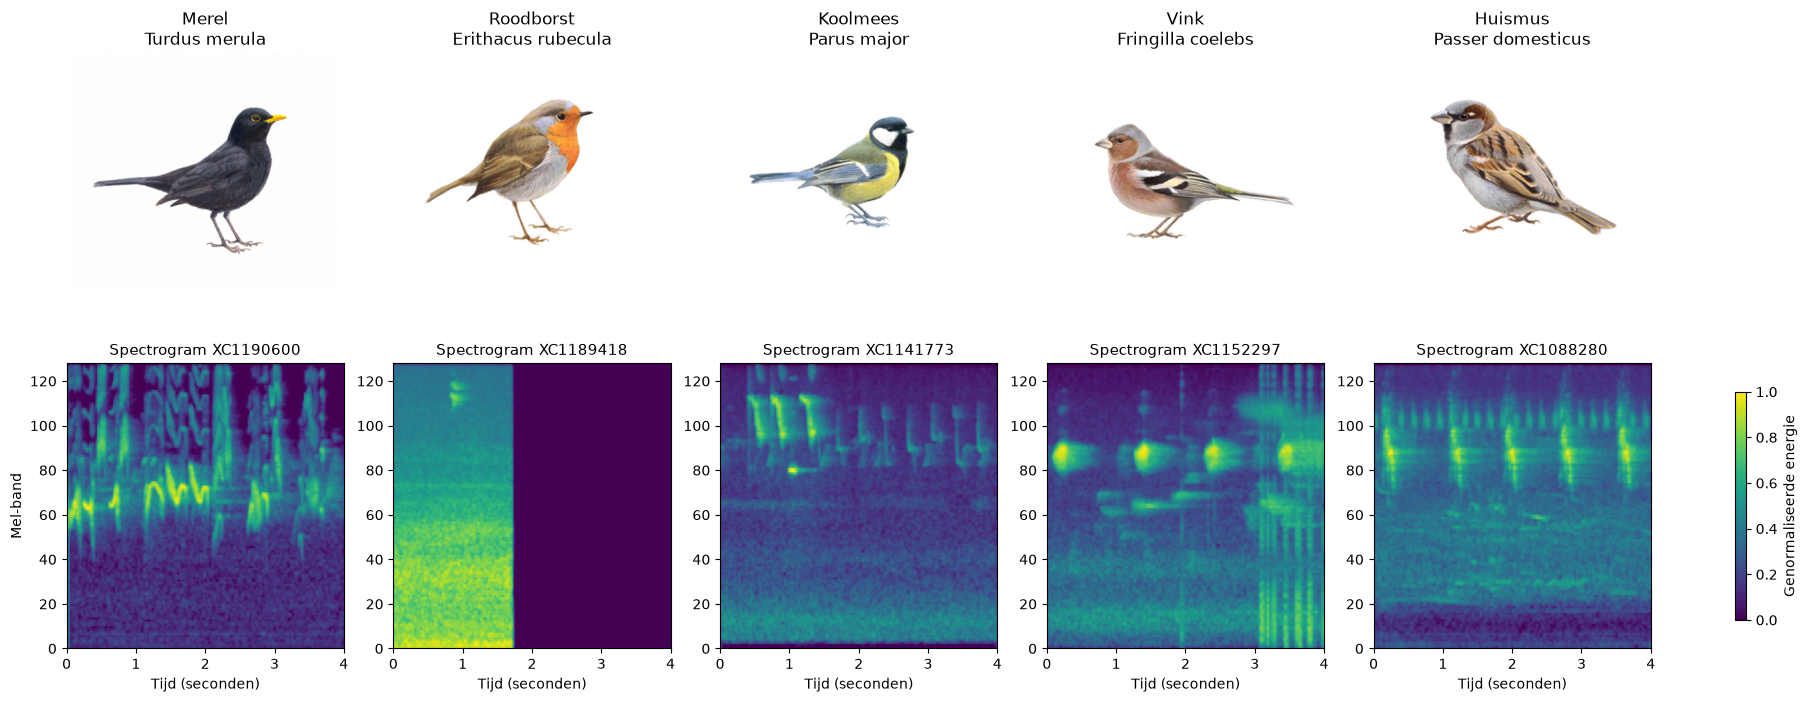

In [4]:
illustratiebestanden = ['merel.png', 'roodborst.png', 'koolmees.png', 'vink.png', 'mus.png']
illustratiemap = projectmap / 'afbeeldingen' / 'notebook'

fig, assen = plt.subplots(
    2, 5, figsize=(18, 7), constrained_layout=True,
    gridspec_kw={'height_ratios': [1.15, 1]},
)
for label, bestandsnaam in enumerate(illustratiebestanden):
    vogelpad = illustratiemap / bestandsnaam
    if not vogelpad.is_file():
        raise FileNotFoundError(f'Vogelillustratie ontbreekt: {vogelpad}')
    assen[0, label].imshow(plt.imread(vogelpad))
    assen[0, label].set_title(
        f'{soortnamen[label]}\n{wetenschappelijke_namen[label]}', fontsize=12,
    )
    assen[0, label].axis('off')

    index = np.flatnonzero(y == label)[0]
    afbeelding = assen[1, label].imshow(
        X[index], origin='lower', aspect='auto', cmap='viridis',
        extent=[0, 4, 0, 128], vmin=0, vmax=1,
    )
    assen[1, label].set_title(f'Spectrogram XC{df.loc[index, "xc_id"]}', fontsize=11)
    assen[1, label].set_xlabel('Tijd (seconden)')

assen[1, 0].set_ylabel('Mel-band')
fig.colorbar(afbeelding, ax=assen[1, :].tolist(), label='Genormaliseerde energie', shrink=0.8)
plt.show()

## 5. Een vaste trainings-, validatie- en testset maken

We richten ons op **60% training, 20% validatie en 20% test**: ongeveer 75, 25 en
25 opnamen. Training leert de gewichten. Validatie bepaalt welke epoch we bewaren.
De testset blijft tot de eindevaluatie buiten het leerproces en de modelselectie.

`StratifiedGroupKFold` maakt vijf groepen met zoveel mogelijk dezelfde
soortverdeling. Groep 0 wordt test, groep 1 validatie en groepen 2–4 samen training.
Dit is alleen een manier om één verdeling te maken, **geen kruisvalidatie-experiment**.
De hash is de groepssleutel: exact gelijke spectrogrammen blijven samen.
Daardoor kunnen aantallen per soort iets afwijken; de tabel toont de echte verdeling.

Elke CSV-rij heeft een unieke oorspronkelijke XC-ID en één clip. Bij een latere
uitbreiding met meerdere segmenten per opname moet óók de oorspronkelijke opname
als groep worden gebruikt. Deze controle herkent geen bijna gelijke opnamen of
opnamen van dezelfde sessie; recordist en sessiegegevens ontbreken in deze CSV.

In [5]:
verdeler = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
df['set'] = 'train'
for groep, (_, indices) in enumerate(verdeler.split(X, y, groups=df['spec_hash'])):
    if groep == 0:
        df.loc[indices, 'set'] = 'test'
    elif groep == 1:
        df.loc[indices, 'set'] = 'validatie'

train_idx = df.index[df['set'] == 'train'].to_numpy(copy=True)
val_idx = df.index[df['set'] == 'validatie'].to_numpy(copy=True)
test_idx = df.index[df['set'] == 'test'].to_numpy(copy=True)

assert df.groupby('xc_id')['set'].nunique().max() == 1
assert df.groupby('spec_hash')['set'].nunique().max() == 1
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(df)
aantallen = pd.crosstab(df['vogelsoort'], df['set']).reindex(
    index=soortnamen, columns=['train', 'validatie', 'test'], fill_value=0,
)
assert (aantallen > 0).all().all(), 'Iedere soort moet in iedere set voorkomen.'
display(aantallen)
print('Totaal per set:', aantallen.sum().to_dict())
display(df.loc[df.spec_hash.duplicated(keep=False), ['xc_id', 'vogelsoort', 'set']])

set,train,validatie,test
vogelsoort,,,
Merel,15,5,5
Roodborst,15,5,5
Koolmees,15,5,5
Vink,15,5,5
Huismus,15,5,5


Totaal per set: {'train': 75, 'validatie': 25, 'test': 25}


,xc_id,vogelsoort,set
58,1167062,Koolmees,test
59,1167063,Koolmees,test


## 6. Van NumPy naar PyTorch-batches

PyTorch rekent met tensors. We voegen één kanaaldimensie toe: de invoervorm
wordt `(aantal, 1, 128, 173)`, vergelijkbaar met een afbeelding in grijstinten.
De labels zijn gehele getallen van 0 tot en met 4.

Een DataLoader levert telkens maximaal 16 voorbeelden. Alleen de trainingsset
wordt iedere epoch geschud. Validatie en test houden hun vaste volgorde, zodat
voorspellingen later bij de juiste XC-ID blijven horen. Er vindt geen augmentatie plaats.

In [6]:
X_tensor = torch.from_numpy(X).unsqueeze(1)
y_tensor = torch.from_numpy(y)

def maak_loader(indices, schudden=False):
    dataset = TensorDataset(X_tensor[indices], y_tensor[indices])
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=schudden, num_workers=0,
        generator=torch.Generator().manual_seed(SEED),
    )

train_loader = maak_loader(train_idx, schudden=True)
val_loader = maak_loader(val_idx)
test_loader = maak_loader(test_idx)
print('Trainingsinvoer:', tuple(X_tensor[train_idx].shape))
print('Aantal trainingsbatches per epoch:', len(train_loader))

Trainingsinvoer: (75, 1, 128, 173)
Aantal trainingsbatches per epoch: 5


## 7. Een klein CNN bouwen

Twee convolutielagen zoeken lokale patronen in tijd en frequentie. ReLU maakt
het mogelijk complexe verbanden te leren. Max-pooling verkleint de representatie.
Adaptive pooling vat de overgebleven patronen samen in een raster van 4 × 4.
De laatste laag geeft vijf scores, de **logits**: één per soort.

`CrossEntropyLoss` vergelijkt deze logits met het juiste label. Er staat geen
softmaxlaag vóór deze loss, omdat PyTorch die berekening intern afhandelt.
Pas bij het tonen van voorspellingen zetten we logits met softmax om naar
relatieve modelscores die samen 1 zijn. We beginnen met willekeurige gewichten.

In [7]:
class VogelCNN(nn.Module):
    def __init__(self, aantal_soorten=5):
        super().__init__()
        self.netwerk = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(16 * 4 * 4, aantal_soorten),
        )

    def forward(self, x):
        return self.netwerk(x)

# Opnieuw initialiseren vanaf dezelfde seed, ook bij herhalen van deze cel.
torch.manual_seed(SEED)
model = VogelCNN(len(soortnamen)).to(apparaat)
criterium = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print('Aantal trainbare parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

VogelCNN(
  (netwerk): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(4, 4))
    (7): Flatten(start_dim=1, end_dim=-1)
    (8): Linear(in_features=256, out_features=5, bias=True)
  )
)
Aantal trainbare parameters: 2533


## 8. Eén trainings- of validatieronde beschrijven

Deze functie doorloopt een DataLoader en berekent gemiddelde loss en accuracy.
Bij training berekent `backward()` hoe de gewichten moeten veranderen en voert
`optimizer.step()` die verandering uit. Bij validatie staan gradiënten uit:
de gewichten worden dan niet aangepast.

De loss wordt gewogen met het aantal voorbeelden, zodat een kleine laatste
batch niet te zwaar meetelt. Accuracy is het aandeel correcte voorspellingen.

In [8]:
def doorloop_epoch(loader, trainen):
    model.train(trainen)
    totale_loss, aantal_goed, aantal = 0.0, 0, 0
    with torch.set_grad_enabled(trainen):
        for invoer, labels in loader:
            invoer, labels = invoer.to(apparaat), labels.to(apparaat)
            if trainen:
                optimizer.zero_grad()
            logits = model(invoer)
            loss = criterium(logits, labels)
            if trainen:
                loss.backward()
                optimizer.step()
            totale_loss += loss.item() * len(labels)
            aantal_goed += (logits.argmax(dim=1) == labels).sum().item()
            aantal += len(labels)
    return totale_loss / aantal, aantal_goed / aantal

## 9. Het model trainen en de beste epoch bewaren

Na elke trainingsronde meten we de validatieloss. We bewaren een kopie van de
gewichten bij de laagste validatieloss en laden die na 30 epochs terug.
De laatste epoch is dus niet automatisch het uiteindelijke model.
De testset wordt hier nergens gebruikt.

Een dalende loss betekent dat het model de juiste antwoorden meer gewicht geeft.
Lage trainingsloss met stijgende validatieloss kan wijzen op overfitting.
De trainingsscores worden gemeten terwijl het model binnen de epoch leert;
de validatiescores worden gemeten na afloop van die epoch.

In [9]:
historie = []
beste_val_loss = float('inf')
beste_gewichten = None
beste_epoch = None
starttijd = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = doorloop_epoch(train_loader, trainen=True)
    val_loss, val_accuracy = doorloop_epoch(val_loader, trainen=False)
    historie.append({
        'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
        'train_accuracy': train_accuracy, 'val_accuracy': val_accuracy,
    })
    if val_loss < beste_val_loss:
        beste_val_loss = val_loss
        beste_epoch = epoch
        beste_gewichten = copy.deepcopy(model.state_dict())
    if epoch == 1 or epoch % 5 == 0:
        print(f'Epoch {epoch:2d}/{EPOCHS} | loss {train_loss:.3f} | '
              f'val_loss {val_loss:.3f} | train acc {train_accuracy:.1%} | '
              f'val acc {val_accuracy:.1%}')

trainingstijd = time.perf_counter() - starttijd
model.load_state_dict(beste_gewichten)
geschiedenis = pd.DataFrame(historie)
print(f'Beste epoch: {beste_epoch}; validatieloss: {beste_val_loss:.4f}')
print(f'Trainingstijd inclusief validatie: {trainingstijd:.1f} seconden.')

Epoch  1/30 | loss 1.617 | val_loss 1.610 | train acc 20.0% | val acc 20.0%


Epoch  5/30 | loss 1.604 | val_loss 1.603 | train acc 20.0% | val acc 32.0%


Epoch 10/30 | loss 1.593 | val_loss 1.590 | train acc 25.3% | val acc 24.0%


Epoch 15/30 | loss 1.562 | val_loss 1.556 | train acc 26.7% | val acc 40.0%


Epoch 20/30 | loss 1.515 | val_loss 1.514 | train acc 30.7% | val acc 36.0%


Epoch 25/30 | loss 1.463 | val_loss 1.482 | train acc 44.0% | val acc 36.0%


Epoch 30/30 | loss 1.389 | val_loss 1.435 | train acc 42.7% | val acc 44.0%
Beste epoch: 30; validatieloss: 1.4347
Trainingstijd inclusief validatie: 4.2 seconden.


## 10. Het leerproces zichtbaar maken

Links staan trainings- en validatieloss (lager is beter), rechts accuracy
(hoger is beter). De stippellijn markeert de gekozen epoch. De horizontale lijn
op 20% is de verwachte accuracy bij uniform willekeurig raden uit vijf soorten.
Een kleine validatieset kan sterk schommelen; beoordeel daarom ook de testresultaten.

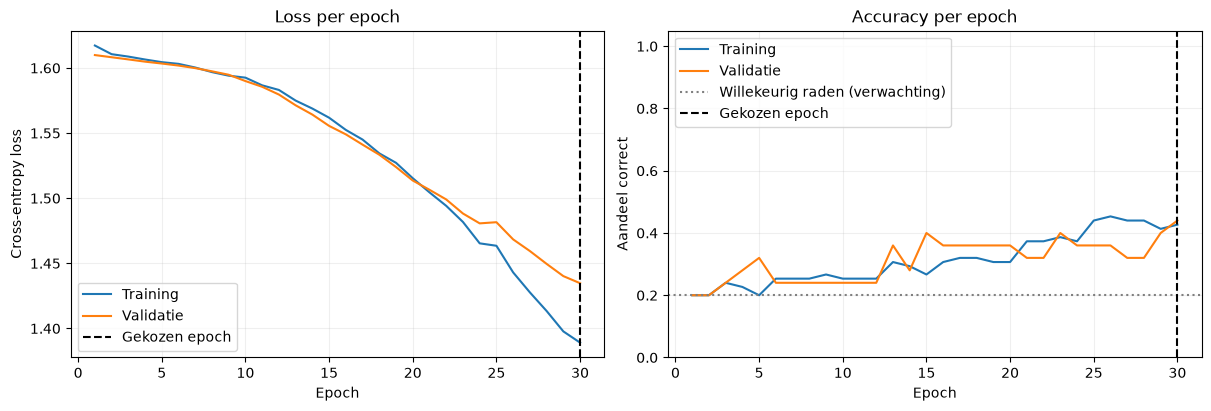

In [10]:
leercurves_fig, assen = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for kolom, label in [('train_loss', 'Training'), ('val_loss', 'Validatie')]:
    assen[0].plot(geschiedenis['epoch'], geschiedenis[kolom], label=label)
for kolom, label in [('train_accuracy', 'Training'), ('val_accuracy', 'Validatie')]:
    assen[1].plot(geschiedenis['epoch'], geschiedenis[kolom], label=label)
assen[0].set(title='Loss per epoch', ylabel='Cross-entropy loss')
assen[1].set(title='Accuracy per epoch', ylabel='Aandeel correct', ylim=(0, 1.05))
assen[1].axhline(0.2, color='gray', linestyle=':', label='Willekeurig raden (verwachting)')
for ax in assen:
    ax.axvline(beste_epoch, color='black', linestyle='--', label='Gekozen epoch')
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.2)
plt.show()

## 11. De apart gehouden testset beoordelen

Nu krijgt het gekozen model voor het eerst de testset. We berekenen:

- **Accuracy:** welk deel van alle testfragmenten is goed voorspeld?
- **Precision per soort:** welk deel van de voorspellingen voor die soort klopt?
- **Recall per soort:** welk deel van de echte voorbeelden van die soort is gevonden?
- **F1 per soort:** een combinatie van precision en recall.
- **Macro-gemiddelden:** het gemiddelde over de vijf soorten, waarbij elke soort even zwaar telt.

`aantal` in de tabel geeft het aantal testvoorbeelden per soort. Als een soort
nooit wordt voorspeld, zetten we de anders ongedefinieerde precision op 0.
Uniform raden heeft bij vijf soorten een verwachte accuracy van 20%; de
meerderheid-baseline voorspelt steeds de meest voorkomende soort uit de trainingsset.
De 20%-referentie is geen verwachte macro-F1 en ook geen significantietoets.

In [11]:
model.eval()
score_batches = []
test_loss_totaal = 0.0
with torch.no_grad():
    for invoer, labels in test_loader:
        logits = model(invoer.to(apparaat))
        test_loss_totaal += criterium(logits, labels.to(apparaat)).item() * len(labels)
        score_batches.append(torch.softmax(logits, dim=1).cpu().numpy())

modelscores = np.concatenate(score_batches)
y_test = y[test_idx]
voorspeld = modelscores.argmax(axis=1)
test_accuracy = accuracy_score(y_test, voorspeld)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, voorspeld, labels=range(5), average='macro', zero_division=0,
)
rapport = classification_report(
    y_test, voorspeld, labels=list(range(5)), target_names=soortnamen,
    output_dict=True, zero_division=0,
)
rapport_tabel = pd.DataFrame(rapport).T.loc[
    soortnamen + ['macro avg', 'weighted avg'], ['precision', 'recall', 'f1-score', 'support']
].rename(columns={'support': 'aantal'})
rapport_tabel['aantal'] = rapport_tabel['aantal'].astype(int)
meerderheidslabel = int(np.bincount(y[train_idx], minlength=5).argmax())
meerderheid_accuracy = accuracy_score(y_test, np.full_like(y_test, meerderheidslabel))

samenvatting = {
    'test_aantal': len(test_idx), 'test_correct': int((y_test == voorspeld).sum()),
    'test_loss': test_loss_totaal / len(test_idx), 'accuracy': float(test_accuracy),
    'macro_precision': float(macro_precision), 'macro_recall': float(macro_recall),
    'macro_f1': float(macro_f1), 'willekeurig_accuracy_verwachting': 0.2,
    'meerderheid_accuracy': float(meerderheid_accuracy),
    'beste_epoch': beste_epoch, 'beste_validatieloss': beste_val_loss,
    'trainingstijd_seconden': trainingstijd,
}
print(f'Test: {samenvatting["test_correct"]}/{len(test_idx)} correct = {test_accuracy:.1%}')
print(f'Macro-precision: {macro_precision:.3f} | Macro-recall: {macro_recall:.3f} | Macro-F1: {macro_f1:.3f}')
print(f'Willekeurig raden: gemiddeld 20% | Meerderheid-baseline: {meerderheid_accuracy:.1%}')
display(rapport_tabel.round(3))

Test: 11/25 correct = 44.0%
Macro-precision: 0.415 | Macro-recall: 0.440 | Macro-F1: 0.404
Willekeurig raden: gemiddeld 20% | Meerderheid-baseline: 20.0%


,precision,recall,f1-score,aantal
Merel,0.200,0.20,0.200,5
Roodborst,1.000,0.60,0.750,5
Koolmees,0.000,0.00,0.000,5
Vink,0.429,0.60,0.500,5
Huismus,0.444,0.80,0.571,5
macro avg,0.415,0.44,0.404,25
weighted avg,0.415,0.44,0.404,25


## 12. Welke soorten worden verward?

De confusion matrix heeft de **werkelijke soort op de rijen** en de **voorspelde
soort op de kolommen**. Getallen op de diagonaal zijn goede voorspellingen;
de overige vakken tonen verwarringen. Het gaat om aantallen fragmenten.
Hiermee zie je wat één totaalscore verbergt, bijvoorbeeld dat twee soorten
vaak door elkaar worden gehaald.

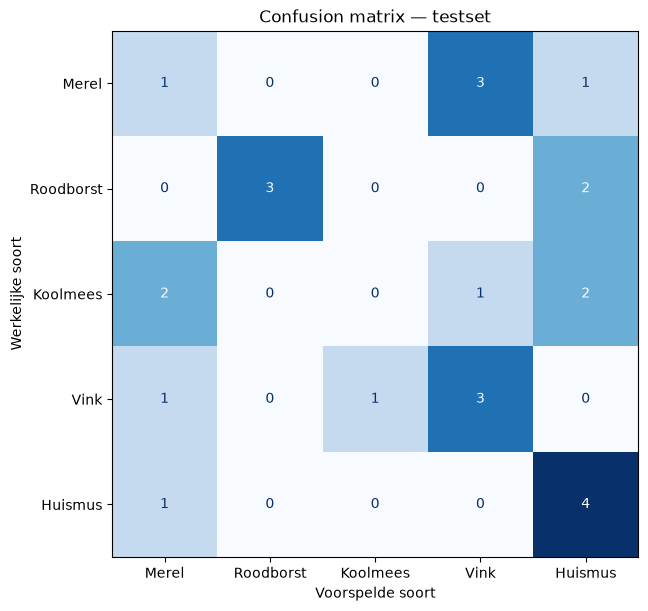

In [12]:
matrix = confusion_matrix(y_test, voorspeld, labels=list(range(5)))
matrix_fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
ConfusionMatrixDisplay(matrix, display_labels=soortnamen).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False,
)
ax.set(title='Confusion matrix — testset', xlabel='Voorspelde soort', ylabel='Werkelijke soort')
plt.show()

## 13. Voorspellingen en fouten terugzoeken

Deze tabel bevat elke testopname met het juiste label, de voorspelling, een
goed/fout-indicatie en vijf softmaxscores. `modelscore` is de score van de
gekozen soort. Een score van bijvoorbeeld 0,80 garandeert geen 80% kans op
een correct antwoord: dit model is niet gekalibreerd.

De fout geclassificeerde fragmenten staan daarna apart. Zo kun je de uitkomst
terugkoppelen aan het type vogelgeluid of de betreffende opname. Dit notebook
kent alleen deze vijf soorten en kiest altijd één ervan, ook bij andere geluiden.

In [13]:
voorspellingen = df.loc[test_idx, ['xc_id', 'vogelsoort', 'type_geluid', 'bestandspad', 'spec_pad']].copy()
voorspellingen = voorspellingen.rename(columns={'vogelsoort': 'werkelijk'})
voorspellingen['voorspeld'] = [soortnamen[i] for i in voorspeld]
voorspellingen['correct'] = y_test == voorspeld
voorspellingen['modelscore'] = modelscores.max(axis=1)
for label, soort in enumerate(soortnamen):
    voorspellingen[f'score_{soort.lower()}'] = modelscores[:, label]
display(voorspellingen.drop(columns=['bestandspad', 'spec_pad']).round(3))
fouten = voorspellingen.loc[~voorspellingen['correct']]
print(f'Aantal fouten: {len(fouten)} van {len(voorspellingen)}.')
display(fouten[['xc_id', 'werkelijk', 'voorspeld', 'type_geluid', 'modelscore']].round(3))

,xc_id,werkelijk,type_geluid,voorspeld,correct,modelscore,score_merel,score_roodborst,score_koolmees,score_vink,score_huismus
2,1191990,Merel,nocturnal flight call,Merel,True,0.364,0.364,0.116,0.108,0.125,0.287
4,1192836,Merel,song,Vink,False,0.321,0.161,0.136,0.263,0.321,0.120
12,1194406,Merel,dawn song,Vink,False,0.299,0.193,0.112,0.270,0.299,0.125
13,1194420,Merel,alarm call,Huismus,False,0.481,0.180,0.105,0.132,0.102,0.481
15,1194451,Merel,dawn song,Vink,False,0.281,0.210,0.226,0.237,0.281,0.046
26,1189985,Roodborst,"call, flight call, nocturnal flight call",Huismus,False,0.447,0.185,0.142,0.111,0.115,0.447
31,1191076,Roodborst,"call, song",Roodborst,True,0.313,0.119,0.313,0.256,0.201,0.110
33,1191078,Roodborst,song,Roodborst,True,0.408,0.121,0.408,0.244,0.150,0.076
38,1191084,Roodborst,song,Roodborst,True,0.415,0.113,0.415,0.251,0.168,0.053
41,1192854,Roodborst,alarm call,Huismus,False,0.374,0.150,0.156,0.124,0.196,0.374


Aantal fouten: 14 van 25.


,xc_id,werkelijk,voorspeld,type_geluid,modelscore
4,1192836,Merel,Vink,song,0.321
12,1194406,Merel,Vink,dawn song,0.299
13,1194420,Merel,Huismus,alarm call,0.481
15,1194451,Merel,Vink,dawn song,0.281
26,1189985,Roodborst,Huismus,"call, flight call, nocturnal flight call",0.447
41,1192854,Roodborst,Huismus,alarm call,0.374
53,1152246,Koolmees,Vink,song,0.445
58,1167062,Koolmees,Merel,"begging call, call",0.298
59,1167063,Koolmees,Merel,"begging call, call",0.298
66,1181778,Koolmees,Huismus,call,0.235


## 14. Eén resultaat bekijken en beluisteren

We bekijken de eerste fout, of de eerste testopname als alles correct is.
Links staat het spectrogram, rechts de vijf modelscores. Daaronder kun je het
oorspronkelijke viersecondenfragment afspelen. `VOORBEELD_INDEX` kun je vervangen
door een andere rij-index uit de tabel hierboven.

Luister bijvoorbeeld of de doelvogel duidelijk hoorbaar is, of meerdere vogels
klinken, of achtergrondgeluid overheerst. Dit zijn aanknopingspunten voor
foutanalyse; een fout op zichzelf bewijst de oorzaak niet.

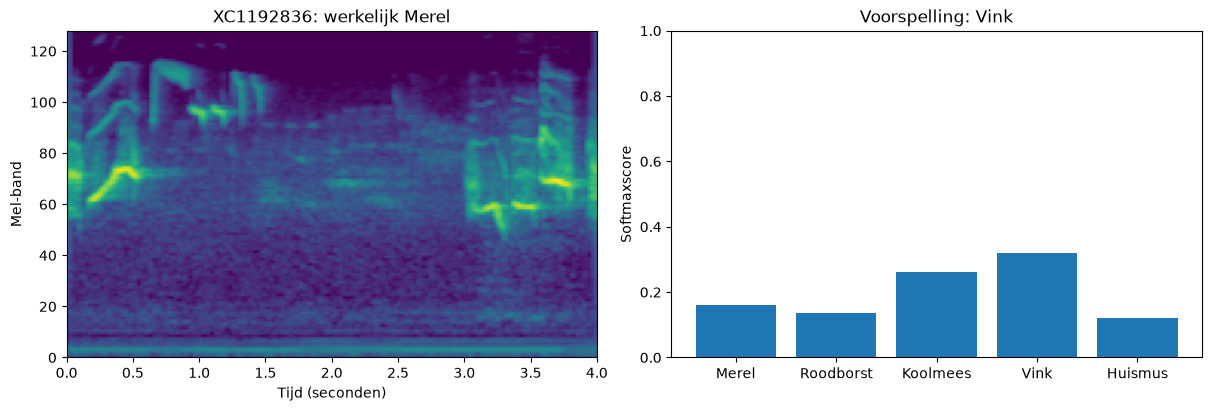

In [14]:
VOORBEELD_INDEX = int(fouten.index[0] if len(fouten) else voorspellingen.index[0])
if VOORBEELD_INDEX not in voorspellingen.index:
    raise ValueError('Kies een rij-index uit de testtabel.')
voorbeeld = voorspellingen.loc[VOORBEELD_INDEX]
positie = voorspellingen.index.get_loc(VOORBEELD_INDEX)
voorbeeld_fig, assen = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
assen[0].imshow(X[VOORBEELD_INDEX], origin='lower', aspect='auto',
                extent=[0, 4, 0, 128], vmin=0, vmax=1)
assen[0].set(xlabel='Tijd (seconden)', ylabel='Mel-band',
             title=f'XC{voorbeeld.xc_id}: werkelijk {voorbeeld.werkelijk}')
assen[1].bar(soortnamen, modelscores[positie])
assen[1].set(ylim=(0, 1), ylabel='Softmaxscore', title=f'Voorspelling: {voorbeeld.voorspeld}')
plt.show()
wav_pad = projectmap / voorbeeld.bestandspad
if wav_pad.is_file():
    display(Audio(filename=str(wav_pad)))
else:
    print('Het bijbehorende WAV-bestand ontbreekt:', wav_pad)

## 15. Model, verdeling en resultaten bewaren

We bewaren de gewichten van de gekozen epoch, alle instellingen, pakketversies,
de precieze dataverdeling met hashes, de leercurves, scores en voorspellingen.
Daarmee kun je deze baseline terugvinden en later vergelijken met één gerichte
verbetering. De bronbestanden in `vogel_dataset_v1` blijven ongewijzigd.

De CSV-bestanden kun je ook buiten Jupyter openen. Het modelbestand bevat
gewichten en labelnamen; bij hergebruik heb je dezelfde `VogelCNN`-architectuur
en dezelfde preprocessing uit `download.py` en `convert.py` nodig.

In [15]:
resultaatmap.mkdir(parents=True, exist_ok=True)
instellingen = {
    'seed': SEED, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'apparaat': str(apparaat),
    'model': 'VogelCNN: Conv8, Conv16, AdaptiveAvgPool4x4, Linear5',
    'optimizer': 'Adam', 'loss': 'CrossEntropyLoss',
    'modelselectie': 'laagste validatieloss', 'augmentatie': False,
    'verdeling': 'StratifiedGroupKFold; groep 0=test, 1=validatie, 2-4=train',
    'groepssleutel': 'SHA256 van float32-spectrogram',
    'aantallen': df['set'].value_counts().to_dict(),
    'unieke_spectrogrammen': int(df.spec_hash.nunique()),
    'invoervorm': [1, 128, 173], 'sample_rate': 22050, 'clipduur_sec': 4,
    'n_fft': 2048, 'hop_length': 512, 'n_mels': 128,
    'normalisatie': 'log-Mel per fragment naar [0, 1], reeds uitgevoerd door convert.py',
    'labelnamen': soortnamen, 'wetenschappelijke_namen': wetenschappelijke_namen,
    'csv_sha256': hashlib.sha256(csv_pad.read_bytes()).hexdigest(),
    'versies': versies,
}
df.to_csv(resultaatmap / 'dataverdeling.csv', index=False)
geschiedenis.to_csv(resultaatmap / 'trainingsverloop.csv', index=False)
rapport_tabel.to_csv(resultaatmap / 'scores_per_soort.csv', index_label='vogelsoort')
voorspellingen.to_csv(resultaatmap / 'testvoorspellingen.csv', index_label='dataset_index')
pd.DataFrame(matrix, index=soortnamen, columns=soortnamen).to_csv(
    resultaatmap / 'confusion_matrix.csv', index_label='werkelijk',
)
for naam, inhoud in [('instellingen.json', instellingen), ('samenvatting.json', samenvatting)]:
    (resultaatmap / naam).write_text(
        json.dumps(inhoud, ensure_ascii=False, indent=2), encoding='utf-8',
    )
torch.save({
    'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
    'labelnamen': soortnamen, 'beste_epoch': beste_epoch, 'invoervorm': [1, 128, 173],
}, resultaatmap / 'vogel_cnn_baseline.pt')
leercurves_fig.savefig(resultaatmap / 'leercurves.png', dpi=150)
matrix_fig.savefig(resultaatmap / 'confusion_matrix.png', dpi=150)
print('Opgeslagen in:', resultaatmap)
for pad in sorted(resultaatmap.iterdir()):
    print(' -', pad.name)

Opgeslagen in: /home/rudy/NextcloudFontys/Master Docent ICT/Semester 3/Masterpiece/dutch-bird-sounds/resultaten/vogelgeluiden_baseline_v1
 - confusion_matrix.csv
 - confusion_matrix.png
 - dataverdeling.csv
 - instellingen.json
 - leercurves.png
 - samenvatting.json
 - scores_per_soort.csv
 - testvoorspellingen.csv
 - trainingsverloop.csv
 - vogel_cnn_baseline.pt


## 16. Eerste conclusie bij deze run

De volgende cel schrijft een korte conclusie op basis van de daadwerkelijk
berekende testresultaten. Die tekst verandert dus mee bij opnieuw uitvoeren.
Hieronder staan de beperkingen die bij de interpretatie horen:

- Met ongeveer vijf testopnamen per soort zijn scores gevoelig voor één fout.
  Bij 25 testopnamen verandert de totale accuracy per fout met vier procentpunt.
- Exact gelijke spectrogrammen zijn bij elkaar gehouden, maar één opname is dubbel
  aanwezig. De dataset bevat 124 unieke voorbeelden. Bij een volgende datasetversie
  kun je het duplicaat vervangen door een nieuwe, onafhankelijke opname.
- De CSV bevat kwaliteit A en zowel zang als roep, maar geen recordist-, locatie-
  of sessiegegevens. Mogelijke samenhang tussen opnamen is dus niet volledig gecontroleerd.
- Dit is één vaste verdeling en één trainingsrun. Een hogere score dan 20% is een
  eerste aanwijzing en bewijst geen statistisch significant verschil of algemene robuustheid.
- Dit experiment meet de invloed van datakwaliteit en achtergrondgeluid nog niet:
  daarvoor is een afzonderlijke vergelijking nodig.
- Gebruik na inzage in deze testresultaten de validatieset voor verdere keuzes;
  herhaald optimaliseren op dezelfde testset maakt die test minder onafhankelijk.

Een logische volgende onderzoeksstap is één vooraf gekozen vorm van augmentatie
vergelijken met deze baseline, met dezelfde vastgelegde verdeling en evaluatiematen.

In [16]:
per_soort = rapport_tabel.loc[soortnamen, 'f1-score']
beste_soorten = ', '.join(per_soort.index[per_soort == per_soort.max()])
lastigste_soorten = ', '.join(per_soort.index[per_soort == per_soort.min()])
vergelijking = 'boven' if test_accuracy > 0.2 else ('op' if test_accuracy == 0.2 else 'onder')
display(Markdown(
    f'**Uitkomst:** het basismodel herkent **{samenvatting["test_correct"]} van '
    f'{len(test_idx)} testfragmenten correct ({test_accuracy:.1%})**. '
    f'De macro-F1 is **{macro_f1:.3f}**. De accuracy ligt {vergelijking} de '
    f'20%-verwachting van uniform willekeurig raden.\n\n'
    f'De hoogste F1 in deze test is voor **{beste_soorten}** '
    f'({per_soort.max():.3f}); de laagste voor **{lastigste_soorten}** '
    f'({per_soort.min():.3f}). Het gebruikte model komt uit epoch **{beste_epoch}**, '
    f'geselecteerd op validatieloss.\n\n'
    'De keten van bestaande spectrogrammen naar training en evaluatie is hiermee '
    'uitgevoerd. De confusion matrix en de beluisterbare fouten geven aanknopingspunten '
    'voor de volgende onderzoeksstap. Deze kleine test zegt nog niet hoe goed het '
    'model buiten werkt of meerdere gelijktijdige vogelsoorten herkent.'
))

**Uitkomst:** het basismodel herkent **11 van 25 testfragmenten correct (44.0%)**. De macro-F1 is **0.404**. De accuracy ligt boven de 20%-verwachting van uniform willekeurig raden.

De hoogste F1 in deze test is voor **Roodborst** (0.750); de laagste voor **Koolmees** (0.000). Het gebruikte model komt uit epoch **30**, geselecteerd op validatieloss.

De keten van bestaande spectrogrammen naar training en evaluatie is hiermee uitgevoerd. De confusion matrix en de beluisterbare fouten geven aanknopingspunten voor de volgende onderzoeksstap. Deze kleine test zegt nog niet hoe goed het model buiten werkt of meerdere gelijktijdige vogelsoorten herkent.